In [ ]:
#part1
# 1. Import important libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# 2. Load the dataset
DATA_PATH = Path("healthcare-dataset-stroke-data.csv")
df = pd.read_csv(DATA_PATH)
print("Dataset shape (rows, columns):", df.shape)

# 3. First 5 rows
display(df.head())

Dataset shape (rows, columns): (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
# 4. Data types, non-null counts, memory usage
print("Dataset info:")
df.info()

# 5. Statistical summaries
print("Numerical summary:")
display(df.describe())
print("Categorical summary:")
display(df.describe(include="object"))

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB
Numerical summary:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


Categorical summary:


C:\Users\Al forsan\AppData\Local\Temp\ipykernel_13096\1881624477.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


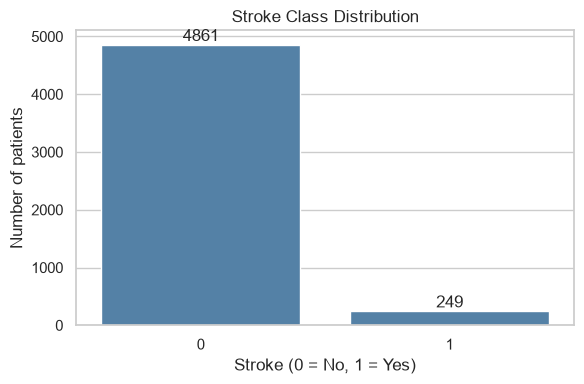

Original class counts:
 stroke
0    4861
1     249
Name: count, dtype: int64
Stroke-positive percentage: 4.87%


In [3]:
# 1. Stroke class distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="stroke", order=[0, 1], color="steelblue", ax=ax)
ax.set(title="Stroke Class Distribution", xlabel="Stroke (0 = No, 1 = Yes)", ylabel="Number of patients")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig("01_stroke_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print("Original class counts:\n", df["stroke"].value_counts().sort_index())
print(f"Stroke-positive percentage: {df['stroke'].mean():.2%}")

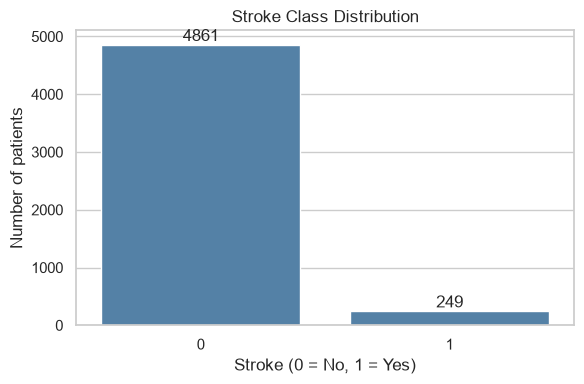

Original class counts:
 stroke
0    4861
1     249
Name: count, dtype: int64
Stroke-positive percentage: 4.87%


In [ ]:
#part2
# 1. Stroke class distribution
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="stroke", order=[0, 1], color="steelblue", ax=ax)
ax.set(title="Stroke Class Distribution", xlabel="Stroke (0 = No, 1 = Yes)", ylabel="Number of patients")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig("01_stroke_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print("Original class counts:\n", df["stroke"].value_counts().sort_index())
print(f"Stroke-positive percentage: {df['stroke'].mean():.2%}")

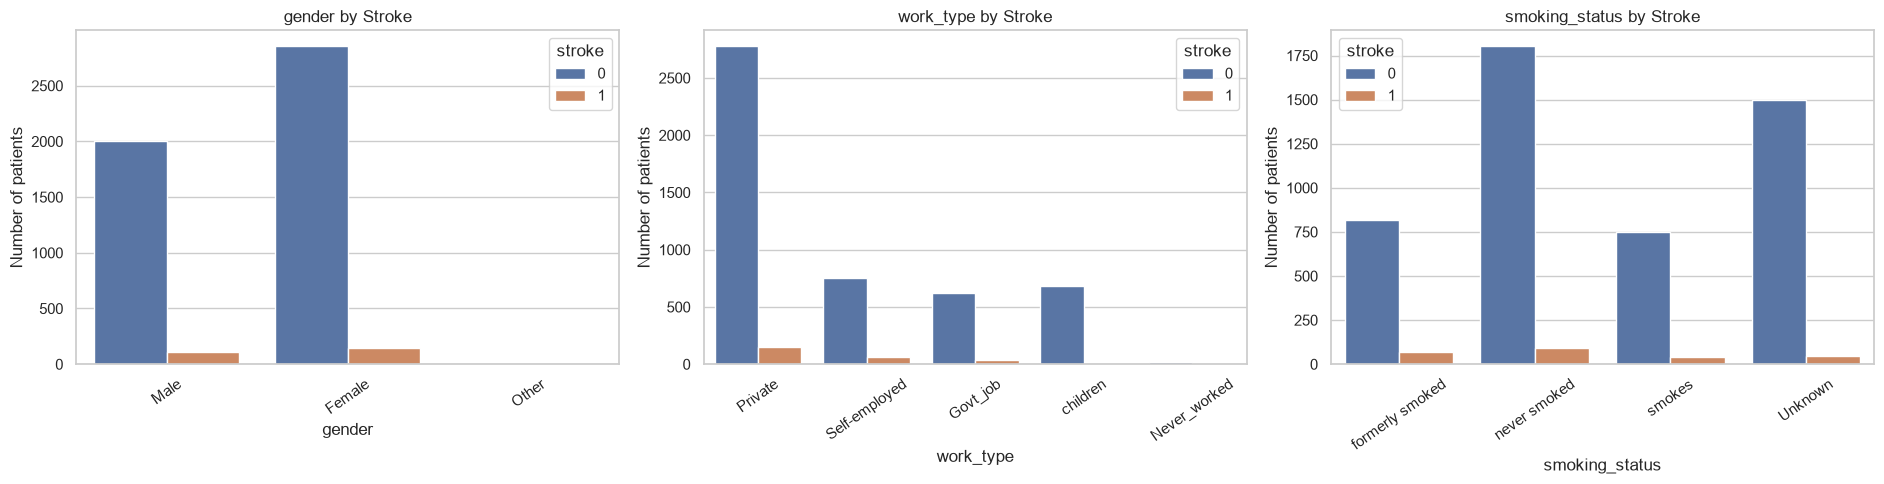

In [5]:
# 2. Countplots for gender, work_type, smoking_status (hue = stroke)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col in zip(axes, ["gender", "work_type", "smoking_status"]):
    sns.countplot(data=df, x=col, hue="stroke", hue_order=[0, 1], palette="deep", ax=ax)
    ax.set_title(f"{col} by Stroke")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of patients")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.savefig("02_categorical_countplots.png", dpi=160, bbox_inches="tight")
plt.show()

In [ ]:
# 3. Drop the 'Other' record
print("Before filtering:", df.shape)
print("'Other' gender records:", (df["gender"] == "Other").sum())
df = df.loc[df["gender"] != "Other"].copy()
print("After filtering:", df.shape)
print("Gender categories remaining:", df["gender"].unique())

Before filtering: (5110, 12)
'Other' gender records: 1
After filtering: (5109, 12)
Gender categories remaining: <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str


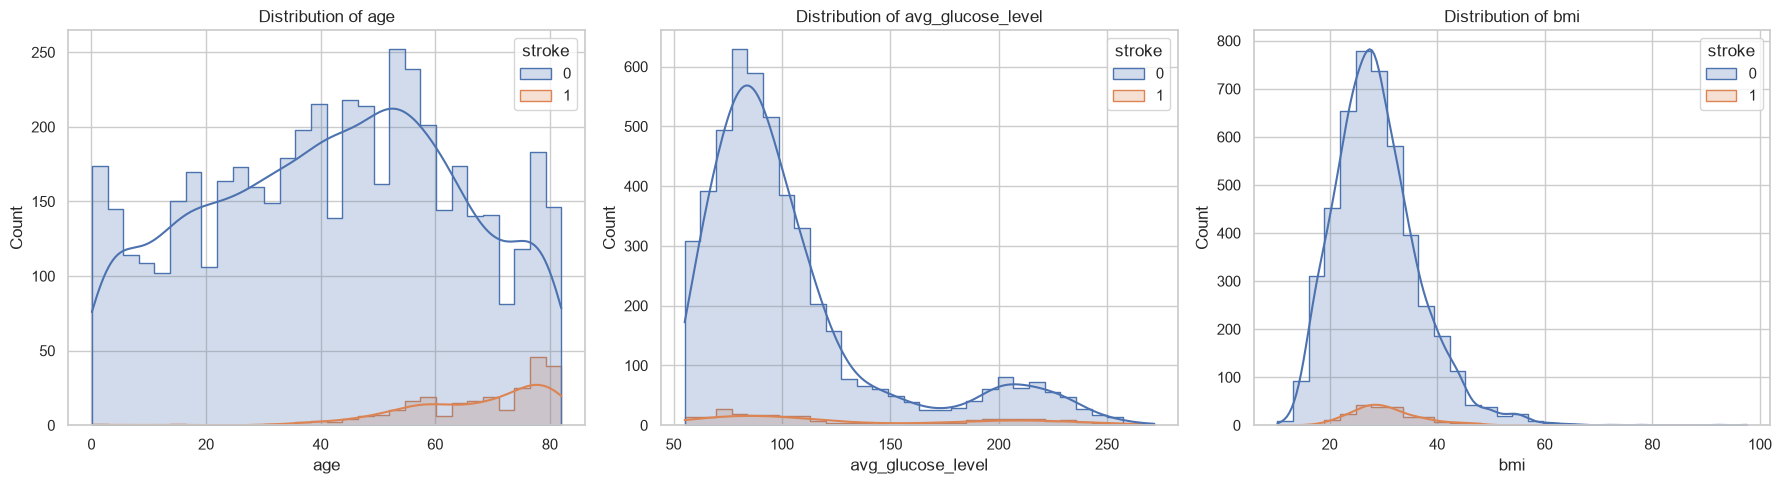

In [7]:
# 4. Histograms + KDE for continuous variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.histplot(data=df, x=col, hue="stroke", hue_order=[0, 1], kde=True,
                 bins=30, element="step", ax=ax)
    ax.set(title=f"Distribution of {col}", xlabel=col, ylabel="Count")
plt.tight_layout()
plt.savefig("03_numeric_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

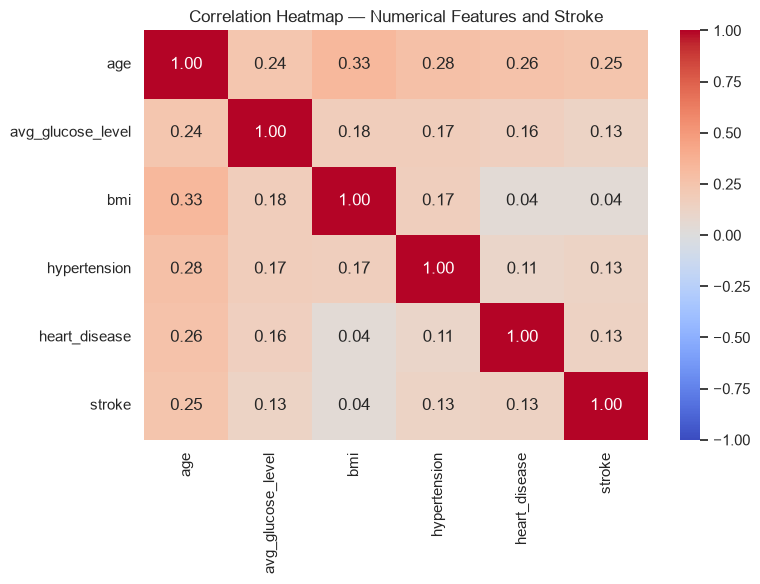

Correlation with stroke:
 stroke               1.000
age                  0.245
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
bmi                  0.042
Name: stroke, dtype: float64


In [8]:
# 5. Correlation heatmap for selected numerical features and stroke
numeric_cols = ["age", "avg_glucose_level", "bmi", "hypertension", "heart_disease", "stroke"]
correlations = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap — Numerical Features and Stroke")
plt.tight_layout()
plt.savefig("04_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
print("Correlation with stroke:\n", correlations["stroke"].sort_values(ascending=False).round(3))

In [ ]:
#part3
# 1. Missing-value counts
print("Missing values before cleaning:")
print(df.isnull().sum())
print("Unknown smoking categories (not NaN):", (df["smoking_status"] == "Unknown").sum())

# 2. Fill missing bmi with median
bmi_median = df["bmi"].median()
missing_bmi_before = df["bmi"].isna().sum()
df["bmi"] = df["bmi"].fillna(bmi_median)
print(f"Filled {missing_bmi_before} missing BMI values using median = {bmi_median:.2f}")

# 3. Verify no missing values remain
print("Missing values after cleaning:")
print(df.isnull().sum())
assert df.isnull().sum().sum() == 0, "Some missing values still remain."

Missing values before cleaning:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
Unknown smoking categories (not NaN): 1544
Filled 201 missing BMI values using median = 28.10
Missing values after cleaning:
id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [ ]:
# 4. Check and remove duplicates
num_duplicates = df.duplicated().sum()
print("Duplicate rows found:", num_duplicates)
df = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df.shape)

# 5. Drop id 
df = df.drop(columns=["id"])
print("Columns after dropping id:", df.columns.tolist())

Duplicate rows found: 0
Shape after duplicate removal: (5109, 12)
Columns after dropping id: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


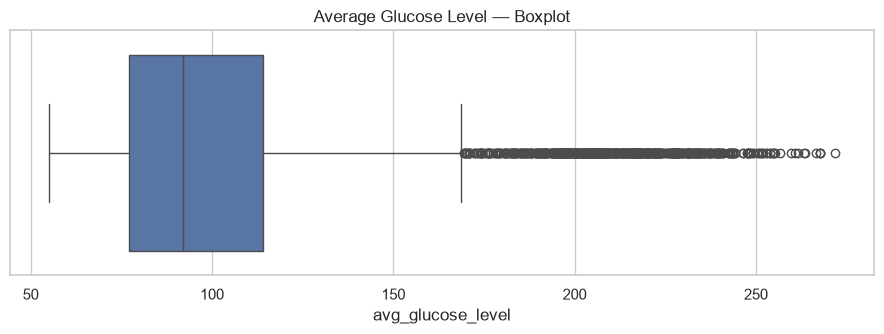

IQR lower bound: 21.96
IQR upper bound: 169.37
Glucose outliers flagged: 627
Decision: retain flagged rows, because elevated glucose could be clinically relevant.
Saved: stroke_cleaned.csv (5109, 11)


In [ ]:
# 6. Boxplot
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(data=df, x="avg_glucose_level", ax=ax)
ax.set_title("Average Glucose Level — Boxplot")
plt.tight_layout()
plt.savefig("05_glucose_boxplot.png", dpi=160, bbox_inches="tight")
plt.show()

q1 = df["avg_glucose_level"].quantile(0.25)
q3 = df["avg_glucose_level"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
is_outlier = ~df["avg_glucose_level"].between(lower_bound, upper_bound)
print(f"IQR lower bound: {lower_bound:.2f}")
print(f"IQR upper bound: {upper_bound:.2f}")
print("Glucose outliers flagged:", is_outlier.sum())
print("Decision: retain flagged rows, because elevated glucose could be clinically relevant.")

# Save cleaned dataset before encoding
clean_df = df.reset_index(drop=True)
clean_df.to_csv("stroke_cleaned.csv", index=False)
print("Saved: stroke_cleaned.csv", clean_df.shape)

In [ ]:
#part4
# 1. List categorical predictors
categorical_cols = ["gender", "work_type", "smoking_status", "ever_married", "Residence_type"]
print("Categorical columns to encode:", categorical_cols)

# 2. Reset index
clean_df = clean_df.reset_index(drop=True)

# 3. One-hot encoding
df_encoded = pd.get_dummies(
    clean_df, columns=categorical_cols, drop_first=False, dtype=int
).reset_index(drop=True)

print("Encoded shape:", df_encoded.shape)
print("All columns:\n", df_encoded.columns.tolist())
display(df_encoded.head())
assert not df_encoded.isnull().any().any()
assert "stroke" in df_encoded.columns
assert all(pd.api.types.is_numeric_dtype(dt) for dt in df_encoded.dtypes)
df_encoded.to_csv("stroke_model_ready_unscaled.csv", index=False)
print("Saved: stroke_model_ready_unscaled.csv")

Categorical columns to encode: ['gender', 'work_type', 'smoking_status', 'ever_married', 'Residence_type']
Encoded shape: (5109, 21)
All columns:
 ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke', 'gender_Female', 'gender_Male', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'ever_married_No', 'ever_married_Yes', 'Residence_type_Rural', 'Residence_type_Urban']


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
0,67.0,0,1,228.69,36.6,1,0,1,0,0,1,0,0,0,1,0,0,0,1,0,1
1,61.0,0,0,202.21,28.1,1,1,0,0,0,0,1,0,0,0,1,0,0,1,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,0,1,0,0,0,0,0,1,0,1,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,0,0,1,0,0,0,1,0,0,1,1,0


Saved: stroke_model_ready_unscaled.csv


In [ ]:
#part5
# 1. Separate features X and target y
X = df_encoded.drop(columns="stroke")
y = df_encoded["stroke"]

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Verify shapes
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)
print("Training class counts (before balancing):\n", y_train.value_counts().sort_index())
print("Testing class counts:\n", y_test.value_counts().sort_index())
assert len(X_train) + len(X_test) == len(df_encoded)

X_train shape: (4087, 20)
X_test shape:  (1022, 20)
y_train shape: (4087,)
y_test shape:  (1022,)
Training class counts (before balancing):
 stroke
0    3888
1     199
Name: count, dtype: int64
Testing class counts:
 stroke
0    972
1     50
Name: count, dtype: int64


In [ ]:
#part6
# 1. Scaler
scaler = StandardScaler()
numerical_to_scale = ["age", "avg_glucose_level", "bmi"]

# 2. Work on copies
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 3. Fit on training data
X_train_scaled[numerical_to_scale] = scaler.fit_transform(X_train[numerical_to_scale])
X_test_scaled[numerical_to_scale] = scaler.transform(X_test[numerical_to_scale])

print("Training-set scaled feature means (near 0):")
print(X_train_scaled[numerical_to_scale].mean().round(5))
print("Training-set scaled feature standard deviations (near 1):")
print(X_train_scaled[numerical_to_scale].std(ddof=0).round(5))
display(X_train_scaled.head())

Training-set scaled feature means (near 0):
age                 -0.0
avg_glucose_level    0.0
bmi                 -0.0
dtype: float64
Training-set scaled feature standard deviations (near 1):
age                  1.0
avg_glucose_level    1.0
bmi                  1.0
dtype: float64


,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
845,0.209397,0,0,-0.821221,0.549234,1,0,0,0,1,0,0,0,0,1,0,0,1,0,1
3744,-0.629845,0,0,-0.485884,-0.988900,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1
4183,-0.364822,0,0,0.302317,-0.769166,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0
3409,-0.232310,0,0,0.062342,0.497532,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0
284,-1.292405,0,0,-0.527297,0.355351,0,1,1,0,0,0,0,1,0,0,0,1,0,0,1


Before oversampling:
 stroke
0    3888
1     199
Name: count, dtype: int64
After oversampling (training only):
 stroke
0    3888
1    3888
Name: count, dtype: int64
Untouched testing distribution:
 stroke
0    972
1     50
Name: count, dtype: int64
X_train_balanced shape: (7776, 20)
y_train_balanced shape: (7776,)


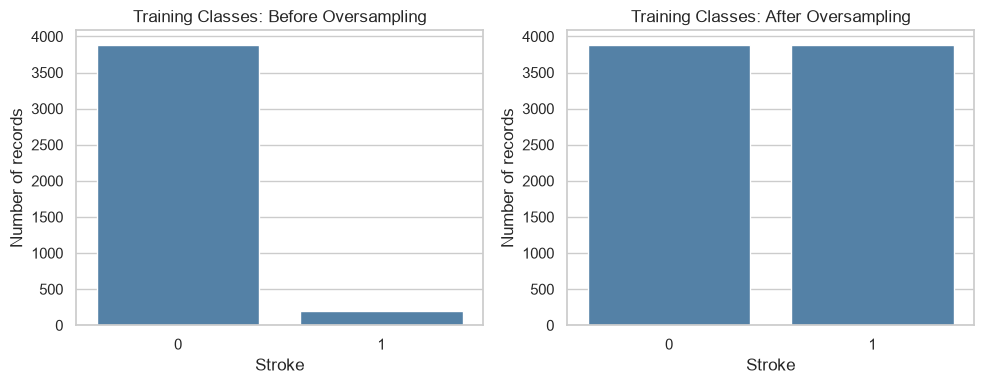

Saved: stroke_train_scaled_balanced.csv, stroke_test_scaled.csv


In [ ]:
#part7
# 1. Original training class distribution
print("Before oversampling:\n", y_train.value_counts().sort_index())

# 2. Random oversampling 
train_with_target = X_train_scaled.copy()
train_with_target["stroke"] = y_train.to_numpy()
majority = train_with_target.loc[train_with_target["stroke"] == 0]
minority = train_with_target.loc[train_with_target["stroke"] == 1]
minority_oversampled = resample(
    minority, replace=True, n_samples=len(majority), random_state=42
)
train_balanced = pd.concat([majority, minority_oversampled], ignore_index=True)
train_balanced = train_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
X_train_balanced = train_balanced.drop(columns="stroke")
y_train_balanced = train_balanced["stroke"]

# 3. Verify balance and maintain untouched test distribution
print("After oversampling (training only):\n", y_train_balanced.value_counts().sort_index())
print("Untouched testing distribution:\n", y_test.value_counts().sort_index())
print("X_train_balanced shape:", X_train_balanced.shape)
print("y_train_balanced shape:", y_train_balanced.shape)
assert y_train_balanced.value_counts().nunique() == 1
assert X_train_balanced.isnull().sum().sum() == 0

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, order=[0, 1], color="steelblue", ax=axes[0])
axes[0].set_title("Training Classes: Before Oversampling")
sns.countplot(x=y_train_balanced, order=[0, 1], color="steelblue", ax=axes[1])
axes[1].set_title("Training Classes: After Oversampling")
for ax in axes:
    ax.set(xlabel="Stroke", ylabel="Number of records")
plt.tight_layout()
plt.savefig("06_train_class_balance.png", dpi=160, bbox_inches="tight")
plt.show()

# Save the final scaled partitions 
train_balanced.to_csv("stroke_train_scaled_balanced.csv", index=False)
test_scaled = X_test_scaled.copy()
test_scaled["stroke"] = y_test.to_numpy()
test_scaled.to_csv("stroke_test_scaled.csv", index=False)
print("Saved: stroke_train_scaled_balanced.csv, stroke_test_scaled.csv")